In [1]:
import os, uuid, hashlib, platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244081126

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python_course
[学号] 20244081126
[机器指纹] 81f3762c7e6b4435
[RUN_ID] 20244081126-81f3762c7e6b4435


In [2]:
# --- 实验1 ---
print("--- 实验1 ---")
a_int = np.array([1, 2, 3])
a_float = np.array([1.0, 2.0, 3.0])
a_bool = np.array([True, False, True])
print("整数 dtype, shape, ndim:", a_int.dtype, a_int.shape, a_int.ndim)

arr = np.arange(12)
arr_2d = arr.reshape(3, 4)
print("形状 (3,4):\n", arr_2d)

print("第2行:", arr_2d[1, :])
print("第1至第3列:\n", arr_2d[:, 0:3])
print("大于6的元素:", arr_2d[arr_2d > 6])

arr_10 = np.arange(10)
print("小于2或大于7:", arr_10[(arr_10 < 2) | (arr_10 > 7)])
print("大于3且小于7:", arr_10[(arr_10 > 3) & (arr_10 < 7)])

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("逐元素乘 *:\n", A * B)
print("矩阵乘 @:\n", A @ B)

# --- 实验2 ---
print("\n--- 实验2 ---")
np.random.seed(42)  # 固定种子
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数, 最小值, 最大值, 均值, 标准差, 极差:", 
      len(scores), np.min(scores), np.max(scores), np.mean(scores), np.std(scores), np.max(scores)-np.min(scores))

arr_1_10 = np.arange(1, 11)
print("均匀抽样:", np.random.choice(arr_1_10, size=5, replace=False))
print("加权抽样:", np.random.choice(arr_1_10, size=5, replace=False, p=arr_1_10/arr_1_10.sum()))

arr_shuffle = np.array([1, 2, 3, 4, 5])
print("保留原数组打乱:", np.random.permutation(arr_shuffle))
print("原地打乱前:", arr_shuffle)
np.random.shuffle(arr_shuffle)
print("原地打乱后:", arr_shuffle)

scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print("普通均值:", np.mean(scores_nan))
print("忽略缺失值均值:", np.nanmean(scores_nan))
print("缺失值个数:", np.sum(np.isnan(scores_nan)))

df_scores = pd.DataFrame({"Index": np.arange(1000), "Score": scores_nan})

--- 实验1 ---
整数 dtype, shape, ndim: int64 (3,) 1
形状 (3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
第2行: [4 5 6 7]
第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
大于6的元素: [ 7  8  9 10 11]
小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]
逐元素乘 *:
 [[ 5 12]
 [21 32]]
矩阵乘 @:
 [[19 22]
 [43 50]]

--- 实验2 ---
样本数, 最小值, 最大值, 均值, 标准差, 极差: 1000 37.58732659930927 100.0 70.18400443523215 9.755086339034765 62.41267340069073
均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]
保留原数组打乱: [5 1 3 2 4]
原地打乱前: [1 2 3 4 5]
原地打乱后: [1 5 2 4 3]
普通均值: nan
忽略缺失值均值: 70.19620743160239
缺失值个数: 3



--- 实验3 ---
方程解 x, y: [2. 3.]
验证 A@sol - b: [0. 0.]
正根: [1.41421356] 成功: True
负根: [-1.41421356] 成功: True
极小值点: [-0.50000001] 函数值: 1.75
t统计量: -8.5515, p值: 3.2930e-15


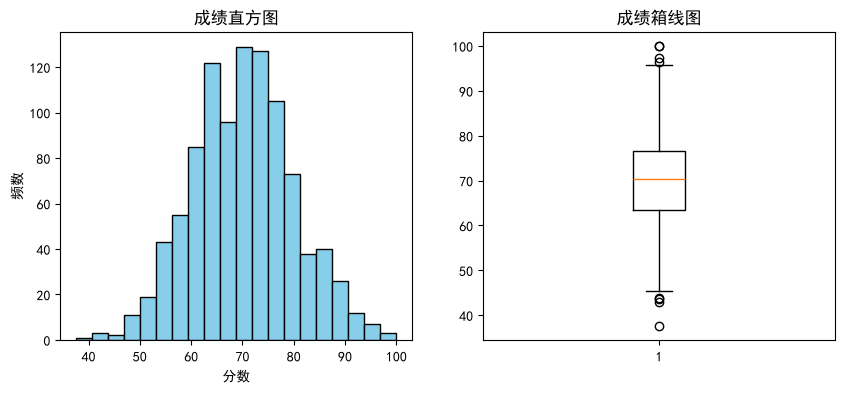

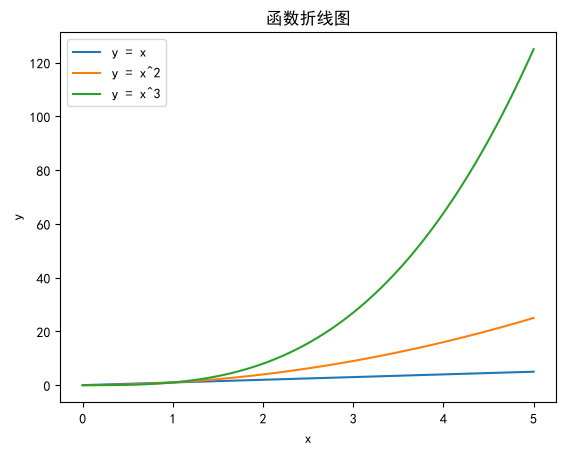

In [3]:
import scipy.linalg
import scipy.optimize
import scipy.stats
import matplotlib.pyplot as plt

# --- 实验3 ---
print("\n--- 实验3 ---")
A_eq = np.array([[3, 1], [1, 2]])
b_eq = np.array([9, 8])
sol = scipy.linalg.solve(A_eq, b_eq)
print("方程解 x, y:", sol)
print("验证 A@sol - b:", A_eq @ sol - b_eq)

func = lambda x: x**2 - 2
root_pos = scipy.optimize.root(func, x0=1.0)
root_neg = scipy.optimize.root(func, x0=-1.0)
print("正根:", root_pos.x, "成功:", root_pos.success)
print("负根:", root_neg.x, "成功:", root_neg.success)

f_min = lambda x: x**2 + x + 2
res_min = scipy.optimize.minimize(f_min, x0=0.0)
print("极小值点:", res_min.x, "函数值:", res_min.fun)

np.random.seed(42)
sample1 = np.random.normal(0, 1, 100)
sample2 = np.random.normal(1, 1, 100)
t_stat, p_val = scipy.stats.ttest_ind(sample1, sample2)
print(f"t统计量: {t_stat:.4f}, p值: {p_val:.4e}")

# 5. 可视化
plt.rcParams['font.sans-serif'] = ['SimHei'] # 解决中文显示问题
plt.rcParams['axes.unicode_minus'] = False

valid_scores = scores_nan[~np.isnan(scores_nan)]
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(valid_scores, bins=20, color='skyblue', edgecolor='black')
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1, 2, 2)
plt.boxplot(valid_scores)
plt.title("成绩箱线图")
plt.show()

x = np.linspace(0, 5, 100)
plt.figure()
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x^2")
plt.plot(x, x**3, label="y = x^3")
plt.title("函数折线图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [4]:
# --- 实验4 ---
print("\n--- 实验4 ---")
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)
print("前3行:\n", df.head(3))

print("\nCarol记录 (loc):\n", df.loc["Carol"])
print("Carol记录 (iloc):\n", df.iloc[2])
print("平均分>=80:\n", df[df["Average"] >= 80])

print("\n列均值 (axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("行均值 (axis=1):\n", df[["Math", "English", "Python"]].mean(axis=1))

df["Max_Score"] = df[["Math", "English", "Python"]].apply(max, axis=1)
print("\n每人最高分:\n", df["Max_Score"])
print("\n每科最小/平均/最大:\n", df[["Math", "English", "Python"]].agg(['min', 'mean', 'max']))
print("\nMath排名:\n", df["Math"].rank(ascending=False))

print("\n按Group统计人数:\n", df.groupby("Group").size())
print("按Group各科平均:\n", df.groupby("Group")[["Math", "English", "Python"]].mean())

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform('mean')
print("\n新增所在组Python平均分:\n", df[["Group", "Python", "Group_Python_Mean"]])

print("\n保留Python平均分>=80的组:\n", df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80))

print("\n协方差矩阵:\n", df[["Math", "English", "Python"]].cov())
print("\n相关系数矩阵:\n", df[["Math", "English", "Python"]].corr())


--- 实验4 ---
前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

Carol记录 (loc):
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
Carol记录 (iloc):
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分>=80:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000

列均值 (axis=0):
 Math       79.833333
English    